### Machine Learning Midterm - Breast Cancer Wisconsin
- **Name:** Hamdi Küçük
- **ID:** 23040102043

In [1]:
import os
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import f_classif
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, adjusted_rand_score)

import ml_helpers as helpers

DATASET_NAME = "breast_cancer"
SEEDS = [42, 52, 62]
TEST_SEED = 42            

os.makedirs("figures", exist_ok=True)
os.makedirs("results/supporting", exist_ok=True)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)


print("Python      :", platform.python_version())
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)
print("seaborn     :", sns.__version__)

Python      : 3.15.0
numpy       : 2.5.4
pandas      : 3.1.1
scikit-learn: 1.9.1
matplotlib  : 3.11.2
seaborn     : 0.13.2


### 1. Loading the Datasets
### 1.1 Load both datasets from scikit-learn

Breast Cancer Wisconsin veri seti Scikit-learn kütüphanesinden yüklenmiş

In [2]:
data = load_breast_cancer()
print(data.DESCR[:600])

.. _breast_cancer_dataset:

Breast cancer Wisconsin (diagnostic) dataset
--------------------------------------------

**Data Set Characteristics:**

:Number of Instances: 569

:Number of Attributes: 30 numeric, predictive attributes and the class

:Attribute Information:
    - radius (mean of distances from center to points on the perimeter)
    - texture (standard deviation of gray-scale values)
    - perimeter
    - area
    - smoothness (local variation in radius lengths)
    - compactness (perimeter^2 / area - 1.0)
    - concavity (severity of concave portions of the contour)
    - concav


### 1.2 Create the data frames
features: `X`, target: `y`
Veri seti 569 satır ve 30 özellikten oluşmaktadır; hedef değişken y olarak ayrılmış, özellik isimleri korunarak X DataFrame'i oluşturulmuştur.

In [3]:
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
class_names = [str(name) for name in data.target_names]
class_labels = [int(label) for label in sorted(y.unique())]

print("Dataset shape (X):", X.shape)
print("Target shape (y) :", y.shape)
print("\nFeature names:", list(X.columns))
print("\nTarget labels:", class_labels)
print("Target names :", class_names)
X.head()

Dataset shape (X): (569, 30)
Target shape (y) : (569,)

Feature names: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Target labels: [0, 1]
Target names : ['malignant', 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:
counts = y.value_counts().sort_index()

class_overview = pd.DataFrame({
    "label": class_labels,
    "class_name": class_names,
    "n_samples": counts.values
})
class_overview["percent"] = (class_overview["n_samples"] / len(y)) * 100

class_overview

,label,class_name,n_samples,percent
0,0,malignant,212,37.258348
1,1,benign,357,62.741652


**Class Label Mapping:** We keep the original scikit-learn labels: **0 = malignant** and **1 = benign**. When discussing errors for malignant cases, class **0** is treated as the positive class.

**Yorum (Interpretation):** Veri setinde 569 örnek ve 30 sayısal özellik var. Sınıflar dengeli değil: 212 malignant (%37.26) ve 357 benign (%62.74).
Bu dengesizlik yüzünden bölmelerde `stratify` kullanıyoruz ve accuracy'nin yanında macro-F1'e de bakıyoruz.
Macro-F1 her iki sınıfa eşit ağırlık verir.

### 2. Dataset Quality Checks
### 2.1 Missing values and duplicates
Veri setinde eksik değer ve tekrarlanan satır bulunmaması nedeniyle bu aşamada imputation yapmadım

In [5]:
missing_table = pd.DataFrame({"missing_count": X.isna().sum()})
missing_table.loc["target"] = y.isna().sum()
print("Total missing values:", int(missing_table["missing_count"].sum()))
missing_table.T

Total missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
missing_count,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [6]:
n_duplicate_feature_rows = int(X.duplicated().sum())
n_duplicate_full_rows = int(pd.concat([X, y], axis=1).duplicated().sum())
print("Duplicate rows (features only)    :", n_duplicate_feature_rows)
print("Duplicate rows (features + target):", n_duplicate_full_rows)
if missing_table["missing_count"].sum() == 0:
    print("-> No missing values are present.")
if n_duplicate_feature_rows == 0:
    print("-> No duplicate rows are present.")

Duplicate rows (features only)    : 0
Duplicate rows (features + target): 0
-> No missing values are present.
-> No duplicate rows are present.


### 2.2 Potential outliers
- **IQR method:** Values below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.
- **z-score method:** Values with $|z| > 3$ (more than 3 standard deviations from the mean).
Aykırı değerler silinmemiş veya kırpılmamış.
KNN ve K-Means gibi mesafe tabanlı algoritmalar büyük değerlerden etkilenebilir.

In [7]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
z_scores = (X - X.mean()) / X.std()

outlier_table = pd.DataFrame({
    "Q1": q1, "Q3": q3, "IQR": iqr,
    "lower_limit": lower_limit, "upper_limit": upper_limit,
    "n_outliers_IQR": ((X < lower_limit) | (X > upper_limit)).sum(),
    "n_outliers_z_gt_3": (z_scores.abs() > 3).sum(),
})
print("Rows with at least one IQR outlier:", int(((X < lower_limit) | (X > upper_limit)).any(axis=1).sum()))
outlier_table.sort_values("n_outliers_IQR", ascending=False).round(3)

Rows with at least one IQR outlier: 171


,Q1,Q3,IQR,lower_limit,upper_limit,n_outliers_IQR,n_outliers_z_gt_3
area error,17.850,45.190,27.340,-23.160,86.200,65,6
radius error,0.232,0.479,0.246,-0.137,0.849,38,7
perimeter error,1.606,3.357,1.751,-1.020,5.984,38,8
worst area,515.300,1084.000,568.700,-337.750,1937.050,35,10
smoothness error,0.005,0.008,0.003,0.001,0.013,30,7
fractal dimension error,0.002,0.005,0.002,-0.001,0.008,28,10
compactness error,0.013,0.032,0.019,-0.016,0.062,28,12
symmetry error,0.015,0.023,0.008,0.003,0.036,27,11
mean area,420.300,782.700,362.400,-123.300,1326.300,25,8
worst fractal dimension,0.071,0.092,0.021,0.041,0.123,24,9


### 2.3 Data types
Bütün özellikler sayısal (float64) türündedir
minimum değer 0 bazılarının

In [8]:
dtype_table = pd.DataFrame({"dtype": X.dtypes.astype(str)})
n_numerical = X.select_dtypes(include="number").shape[1]
n_categorical = X.shape[1] - n_numerical
print("Numerical features  :", n_numerical)
print("Categorical features:", n_categorical)
print("Target dtype        :", y.dtype)
dtype_table.T

Numerical features  : 30
Categorical features: 0
Target dtype        : int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


### 3. Exploratory Data Analysis (EDA)



### 3.1 Descriptive Statistics
Özelliklerin ölçüm aralıkları ve standart sapmaları birbirinden farklıdır. Özellikle area gibi özelliklerde değer aralığı oldukça geniştir.

In [9]:
descriptive_stats = pd.DataFrame({
    "mean": X.mean(),
    "median": X.median(),
    "min": X.min(),
    "max": X.max(),
    "std": X.std(),
    "Q1": X.quantile(0.25),
    "Q3": X.quantile(0.75),
})
descriptive_stats.to_csv(f"results/supporting/{DATASET_NAME}_descriptive_stats.csv")
descriptive_stats.round(4)

,mean,median,min,max,std,Q1,Q3
mean radius,14.1273,13.3700,6.9810,28.1100,3.5240,11.7000,15.7800
mean texture,19.2896,18.8400,9.7100,39.2800,4.3010,16.1700,21.8000
mean perimeter,91.9690,86.2400,43.7900,188.5000,24.2990,75.1700,104.1000
mean area,654.8891,551.1000,143.5000,2501.0000,351.9141,420.3000,782.7000
mean smoothness,0.0964,0.0959,0.0526,0.1634,0.0141,0.0864,0.1053
mean compactness,0.1043,0.0926,0.0194,0.3454,0.0528,0.0649,0.1304
mean concavity,0.0888,0.0615,0.0000,0.4268,0.0797,0.0296,0.1307
mean concave points,0.0489,0.0335,0.0000,0.2012,0.0388,0.0203,0.0740
mean symmetry,0.1812,0.1792,0.1060,0.3040,0.0274,0.1619,0.1957
mean fractal dimension,0.0628,0.0615,0.0500,0.0974,0.0071,0.0577,0.0661


### 3.2 Class distribution and correlations

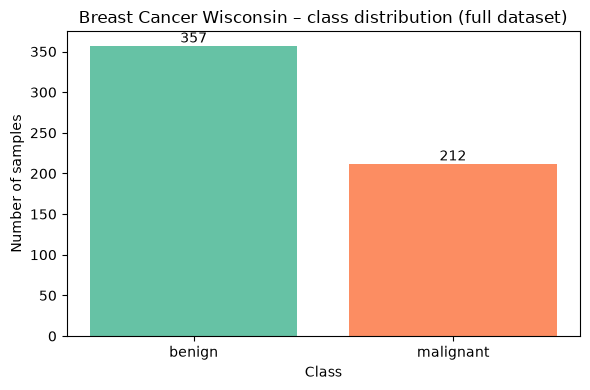

In [10]:
class_counts = y.value_counts().rename(index={0: class_names[0], 1: class_names[1]})
plt.figure(figsize=(6, 4))
bars = plt.bar(class_counts.index, class_counts.values, color=sns.color_palette("Set2", len(class_names)))
plt.bar_label(bars)
plt.title("Breast Cancer Wisconsin – class distribution (full dataset)")
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_01_class_distribution.png", dpi=150)
plt.show()

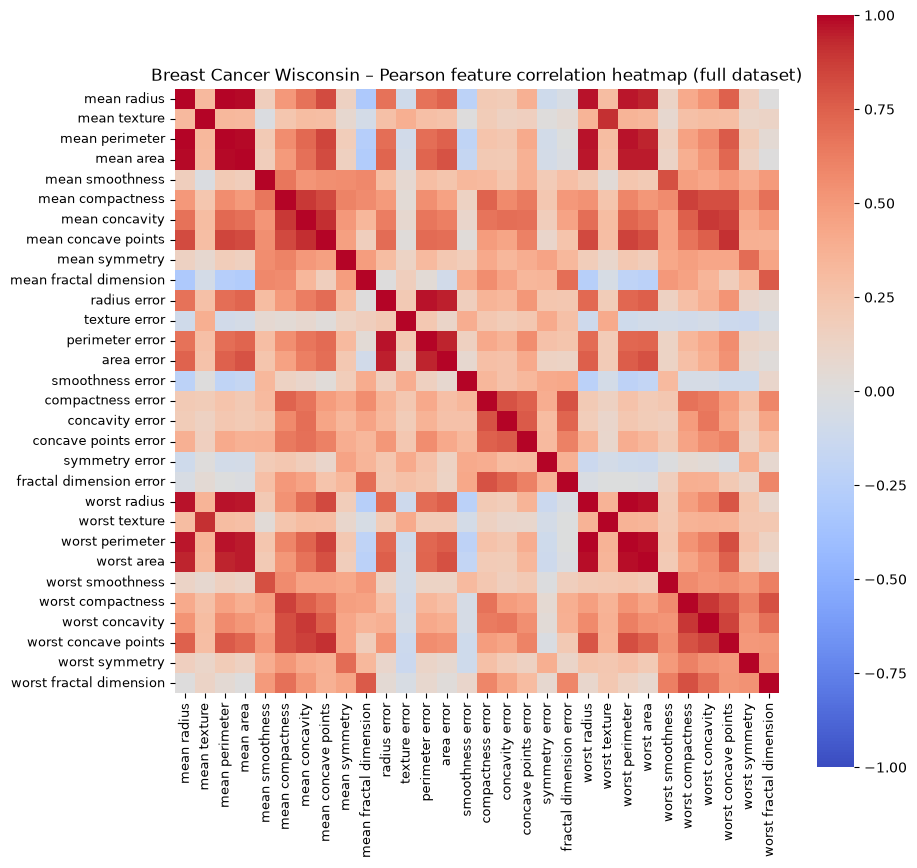

In [11]:
correlation = X.corr(method="pearson")
plt.figure(figsize=(9.5, 9))
sns.heatmap(correlation, cmap="coolwarm", vmin=-1, vmax=1, annot=False, fmt=".2f", square=True,
            annot_kws={"size": 9})
plt.xticks(fontsize=9)
plt.yticks(fontsize=9)
plt.title("Breast Cancer Wisconsin – Pearson feature correlation heatmap (full dataset)")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_02_correlation_heatmap.png", dpi=150)
plt.show()

In [12]:
upper_triangle = np.triu(np.ones(correlation.shape, dtype=bool), k=1)
pairs = correlation.where(upper_triangle).stack().reset_index()
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
pairs["abs_r"] = pairs["pearson_r"].abs()
top3_pairs = pairs.sort_values("abs_r", ascending=False).head(3).reset_index(drop=True)
top3_pairs.to_csv(f"results/supporting/{DATASET_NAME}_top3_correlation_pairs.csv", index=False)
top3_pairs.round(4)

,feature_1,feature_2,pearson_r,abs_r
0,mean radius,mean perimeter,0.9979,0.9979
1,worst radius,worst perimeter,0.9937,0.9937
2,mean radius,mean area,0.9874,0.9874


### 3.3 Boxplots
Boxplot grafiklerinde bazı özelliklerin sınıfları ayırmada daha belirgin olduğu, bazı özelliklerde ise sınıfların değerlerinin örtüştüğü görüldü

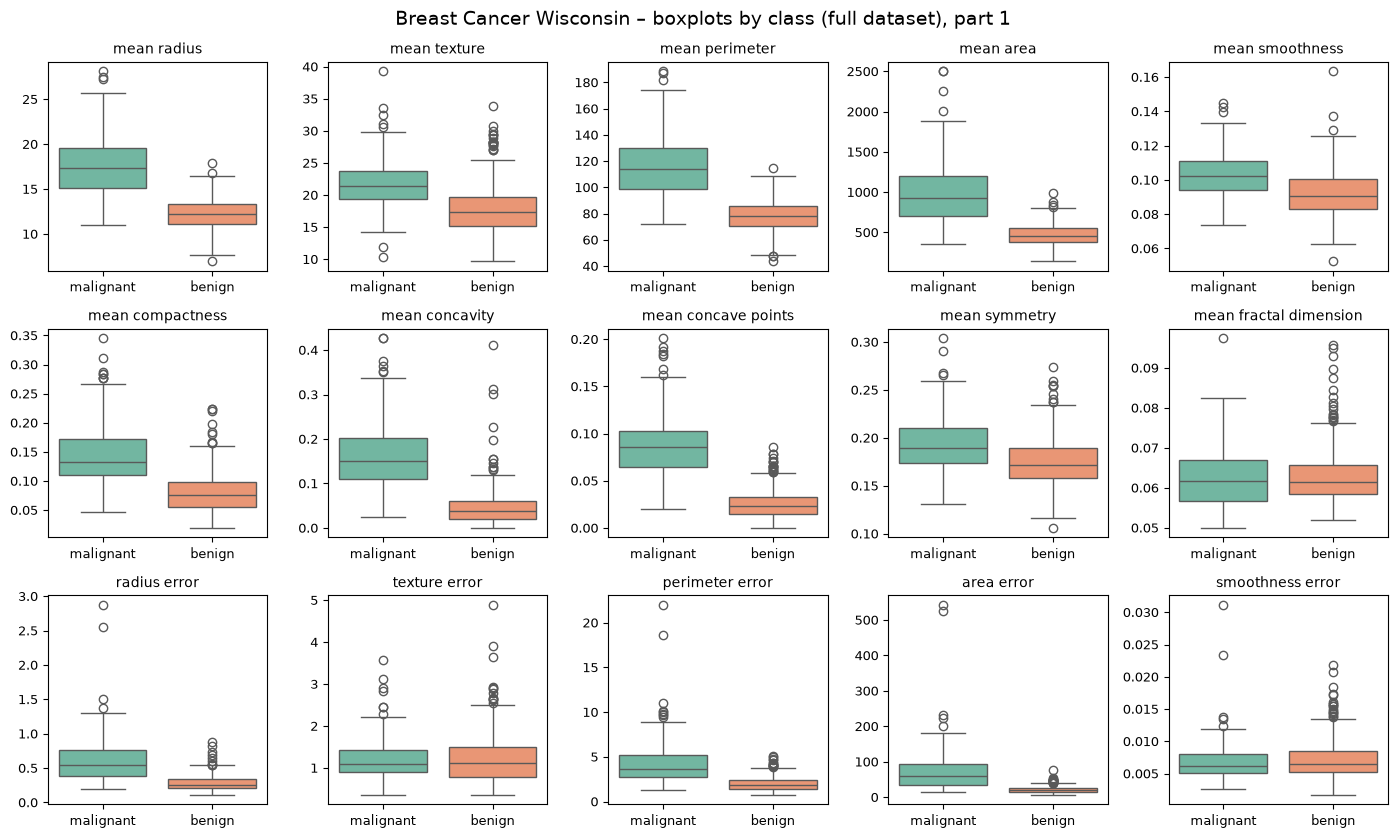

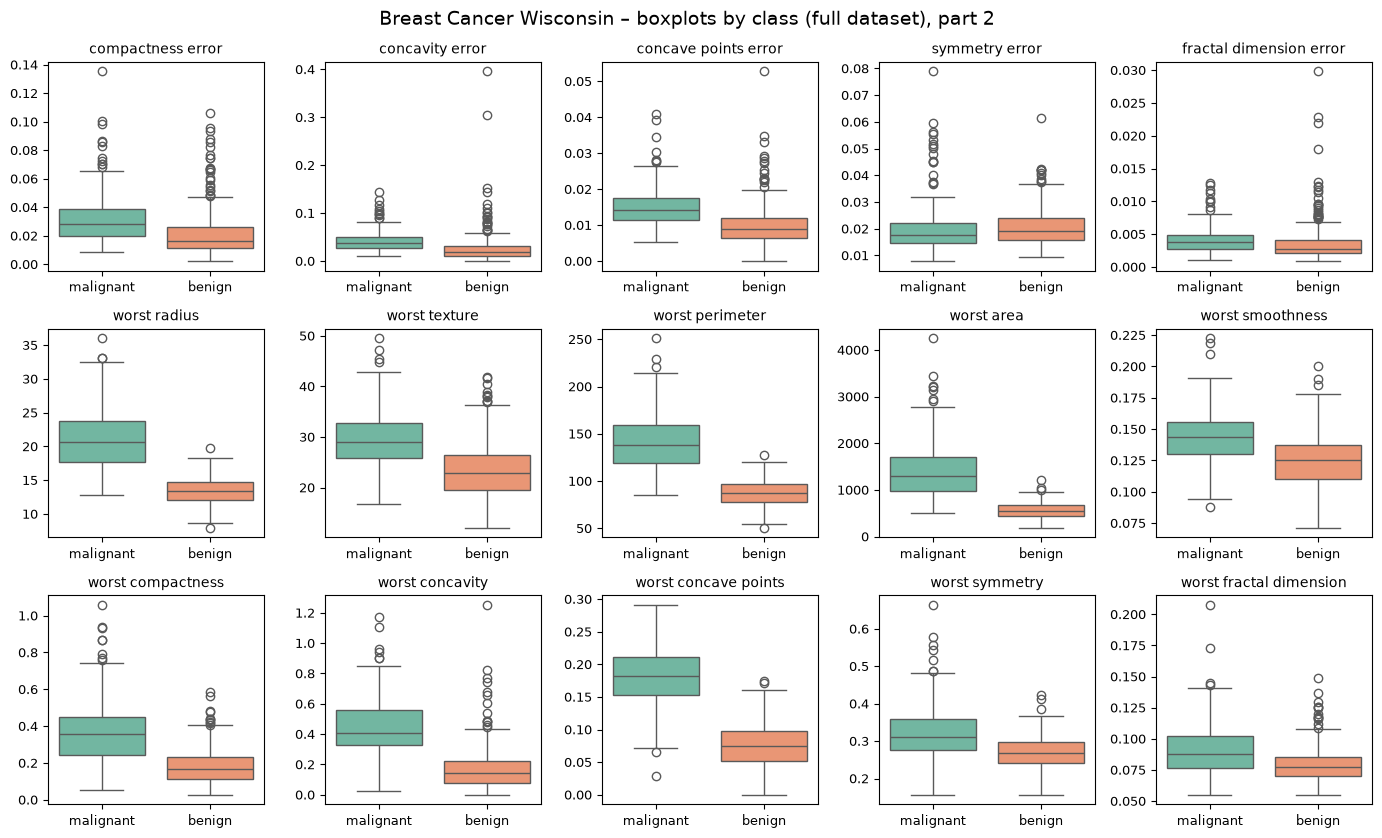

In [13]:
features = list(X.columns)
features_per_figure = 15
class_name_series = y.map({0: class_names[0], 1: class_names[1]}).rename("class")

for figure_number, start in enumerate(range(0, len(features), features_per_figure), start=1):
    chunk = features[start:start + features_per_figure]
    fig, axes = plt.subplots(3, 5, figsize=(14, 8.5))
    axes = axes.flatten()
    for ax, feature in zip(axes, chunk):
        
        sns.boxplot(x=class_name_series, y=X[feature], hue=class_name_series, order=class_names,
                    palette="Set2", legend=False, ax=ax)
        ax.set_title(feature, fontsize=10)
        ax.tick_params(labelsize=9)
        ax.set_xlabel("")
        ax.set_ylabel("")
    for ax in axes[len(chunk):]:
        ax.axis("off")
    fig.suptitle(f"Breast Cancer Wisconsin – boxplots by class (full dataset), part {figure_number}", fontsize=14)
    fig.tight_layout()
    fig.savefig(f"figures/{DATASET_NAME}_03_boxplots_part{figure_number}.png", dpi=120)
    plt.show()

## 4. Splitting the Datasets

### 4.1 Test setini sabitleme ve Eğitim/Doğrulama ayrımı
1. Önce verinin **%20'sini test seti** olarak bir kenara ayıracağım (`random_state=42`, `stratify=y`). Bu test setine ödev boyunca bir daha hiç dokunmayacağım.
2. Kalan %80'lik kısmı ise 3 farklı seed (42, 52, 62) kullanarak eğitim ve doğrulama setlerine böleceğim (`test_size=0.125`). 
3. Böylece elimde net olarak **%70 Eğitim, %10 Doğrulama, %20 Test** verisi olacak.
Farklı seed değerleri sadece eğitim ve doğrulama verilerini kendi içinde karıştıracak, test setim hep aynı kalacak. `stratify=y` ile sınıfların dağılım dengesini koruyorum. DataFrame üzerinden işlem yaptığım için de satır numaralarım (indexler) hiç bozulmuyor. Bu kadar.

In [14]:
X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)

splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed)
    splits[seed] = {
        "X_train": X_train, "X_val": X_val,
        "y_train": y_train, "y_val": y_val,
        "test_index": X_test.index.copy(), #her seed için aynı burası
    }
    print(f"seed {seed}: train={len(X_train)}, validation={len(X_val)}, test={len(X_test)}")

seed 42: train=398, validation=57, test=114
seed 52: train=398, validation=57, test=114
seed 62: train=398, validation=57, test=114


### 4.2 Verify the split

In [15]:
summary_rows = []
for seed in SEEDS:
    subsets = {
        "train": splits[seed]["y_train"],
        "validation": splits[seed]["y_val"],
        "test": y_test,
    }
    for subset_name, labels in subsets.items():
        row = {"seed": seed, "subset": subset_name, "n_samples": len(labels),
               "percent_of_full": round(100 * len(labels) / len(y), 2)}
        for label in class_labels:
            row[f"n_{class_names[label]}"] = int((labels == label).sum())
        summary_rows.append(row)

split_summary = pd.DataFrame(summary_rows)
split_summary.to_csv(f"results/supporting/{DATASET_NAME}_split_summary.csv", index=False)
split_summary

,seed,subset,n_samples,percent_of_full,n_malignant,n_benign
0,42,train,398,69.95,149,249
1,42,validation,57,10.02,21,36
2,42,test,114,20.04,42,72
3,52,train,398,69.95,149,249
4,52,validation,57,10.02,21,36
5,52,test,114,20.04,42,72
6,62,train,398,69.95,149,249
7,62,validation,57,10.02,21,36
8,62,test,114,20.04,42,72


In [16]:
# çakışma yok her seed için toplam var 
for seed in SEEDS:
    train_idx = set(splits[seed]["X_train"].index)
    val_idx = set(splits[seed]["X_val"].index)
    test_idx = set(splits[seed]["test_index"])
    
    no_overlap = (len(train_idx & val_idx) == 0 and len(train_idx & test_idx) == 0 and len(val_idx & test_idx) == 0)
    total = len(train_idx) + len(val_idx) + len(test_idx)
    covers_all = (train_idx | val_idx | test_idx) == set(X.index)
    
    print(f"seed {seed}: no overlap = {no_overlap}, total = {total} (dataset = {len(X)}), covers all rows = {covers_all}")
    assert no_overlap and total == len(X) and covers_all

first_seed_test = splits[SEEDS[0]]["test_index"]
same_test = True
for seed in SEEDS:
    if not splits[seed]["test_index"].equals(first_seed_test):
        same_test = False
        break

print("Test indices identical across all three seeds:", same_test)
assert same_test

seed 42: no overlap = True, total = 569 (dataset = 569), covers all rows = True
seed 52: no overlap = True, total = 569 (dataset = 569), covers all rows = True
seed 62: no overlap = True, total = 569 (dataset = 569), covers all rows = True
Test indices identical across all three seeds: True


In [17]:
index_rows = []

for seed in SEEDS:
    
    for row_index in splits[seed]["X_train"].index:
        index_rows.append({"seed": seed, "subset": "train", "row_index": int(row_index)})
        
    for row_index in splits[seed]["X_val"].index:
        index_rows.append({"seed": seed, "subset": "validation", "row_index": int(row_index)})
        
    for row_index in splits[seed]["test_index"]:
        index_rows.append({"seed": seed, "subset": "test", "row_index": int(row_index)})

split_indices = pd.DataFrame(index_rows)
split_indices.to_csv(f"results/{DATASET_NAME}_split_indices.csv", index=False)

print("Saved:", f"results/{DATASET_NAME}_split_indices.csv", "-", len(split_indices), "rows")
print("First 10 test row indices:", sorted(X_test.index)[:10])
print("First 10 training row indices (seed 42):", sorted(splits[42]["X_train"].index)[:10])

Saved: results/breast_cancer_split_indices.csv - 1707 rows
First 10 test row indices: [1, 14, 20, 23, 24, 41, 51, 64, 70, 73]
First 10 training row indices (seed 42): [0, 2, 3, 4, 5, 6, 8, 9, 10, 11]


Her seed'de toplam 569 örnek korunmuştur.
Train, validation ve test kümeleri kendi içinde çakışmamaktadır.
Test kümesi üç seed boyunca sabit tutulmuştur.
Seed değiştiğinde yalnızca eğitim ve doğrulama örnekleri değişmektedir

### 5. Data Preprocessing and Scaling
### 5.1 Handle missing values, if present

In [18]:
total_missing = int(X.isna().sum().sum())
if total_missing == 0:
    print("No missing values exist -> no imputation step is added.")
else:
    print("Missing values found:", total_missing, "-> a training-only imputer would be needed.")

No missing values exist -> no imputation step is added.


### 5.2 Select one scaler
StandardScaler, özellikleri ortalama 0 ve standart sapma 1 olacak şekilde dönüştürür.
(Deneylere başlamadan önce **StandardScaler** seçtik. Özelliklerin eğitim ortalamasını çıkarıp standart sapmasına bölüyor. Böylece ortalama 0, standart sapma 1 oluyor. Derste de gördüğümüz gibi KNN gibi mesafe tabanlı modeller ölçeğe çok duyarlıdır bu yüzden bu adım şart.)

### 5.3 Fit and apply the scaler correctly
Her seed için ayrı StandardScaler oluşturulmuştur.
Scaler yalnızca eğitim verisine fit edilmiştir.
Validation ve test verileri scalera fit edilmeden dönüştürülmüştür.
Bu yöntem data leakage oluşmasını önler

In [19]:
scalers = {}
for seed in SEEDS:
    X_train = splits[seed]["X_train"]
    X_val = splits[seed]["X_val"]

    scaler = StandardScaler()
    scaler.fit(X_train)                    
    scalers[seed] = scaler

    X_train_scaled = pd.DataFrame(scaler.transform(X_train), index=X_train.index, columns=X.columns)
    X_val_scaled = pd.DataFrame(scaler.transform(X_val), index=X_val.index, columns=X.columns)

    splits[seed]["unscaled"] = {"train": X_train, "val": X_val}
    splits[seed]["scaled"] = {"train": X_train_scaled, "val": X_val_scaled}


X_test_scaled = pd.DataFrame(scalers[TEST_SEED].transform(X_test), index=X_test.index, columns=X.columns)
print("Fitted scalers in this notebook:", len(scalers))

Fitted scalers in this notebook: 3


In [20]:
print("Seed 42 – first five TRAINING rows BEFORE scaling:")
display(splits[42]["unscaled"]["train"].head().round(3))
print("Seed 42 – first five TRAINING rows AFTER StandardScaler:")
display(splits[42]["scaled"]["train"].head().round(3))

Seed 42 – first five TRAINING rows BEFORE scaling:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,12.46,19.89,80.43,471.3,0.085,0.101,0.068,0.031,0.178,0.062,0.364,1.040,2.579,28.32,0.007,0.034,0.047,0.014,0.027,0.005,13.46,23.07,88.13,551.3,0.105,0.216,0.190,0.076,0.268,0.078
390,10.26,12.22,65.75,321.6,0.100,0.075,0.019,0.020,0.180,0.066,0.191,0.548,1.348,11.88,0.006,0.014,0.008,0.007,0.019,0.002,11.38,15.65,73.23,394.5,0.134,0.165,0.086,0.067,0.294,0.077
420,11.57,19.04,74.20,409.7,0.085,0.077,0.055,0.014,0.203,0.063,0.286,1.440,2.206,20.30,0.007,0.020,0.044,0.009,0.019,0.003,13.07,26.98,86.43,520.5,0.125,0.194,0.256,0.067,0.304,0.083
356,13.05,18.59,85.09,512.0,0.108,0.130,0.096,0.056,0.204,0.065,0.311,1.510,2.590,21.57,0.008,0.039,0.051,0.019,0.029,0.006,14.19,24.85,94.22,591.2,0.134,0.266,0.257,0.126,0.311,0.083
446,17.75,28.03,117.30,981.6,0.100,0.131,0.170,0.083,0.171,0.059,0.390,1.077,2.873,43.95,0.005,0.020,0.037,0.011,0.012,0.003,21.53,38.54,145.40,1437.0,0.140,0.376,0.640,0.197,0.297,0.091


Seed 42 – first five TRAINING rows AFTER StandardScaler:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
301,-0.465,0.177,-0.468,-0.519,-0.884,-0.073,-0.281,-0.467,-0.077,-0.069,-0.131,-0.290,-0.127,-0.265,-0.179,0.412,0.414,0.350,0.727,0.294,-0.573,-0.379,-0.561,-0.578,-1.226,-0.259,-0.416,-0.585,-0.340,-0.358
390,-1.084,-1.553,-1.065,-0.944,0.251,-0.554,-0.869,-0.753,-0.010,0.375,-0.766,-1.168,-0.737,-0.644,-0.444,-0.659,-0.741,-0.766,-0.168,-0.524,-1.001,-1.547,-1.000,-0.855,0.070,-0.573,-0.893,-0.724,0.046,-0.381
420,-0.715,-0.015,-0.721,-0.694,-0.814,-0.521,-0.442,-0.889,0.806,-0.044,-0.416,0.424,-0.312,-0.450,0.056,-0.294,0.334,-0.472,-0.246,-0.177,-0.654,0.237,-0.611,-0.633,-0.346,-0.396,-0.117,-0.728,0.196,-0.074
356,-0.299,-0.116,-0.278,-0.403,0.855,0.463,0.052,0.166,0.821,0.281,-0.328,0.549,-0.121,-0.421,0.221,0.712,0.533,1.093,0.861,0.676,-0.423,-0.099,-0.382,-0.508,0.070,0.049,-0.111,0.155,0.315,-0.055
446,1.024,2.013,1.034,0.933,0.251,0.482,0.936,0.846,-0.317,-0.532,-0.038,-0.224,0.019,0.095,-0.748,-0.311,0.110,-0.111,-0.950,-0.457,1.086,2.057,1.128,0.984,0.327,0.731,1.638,1.218,0.100,0.359


In [21]:
#eğitim verisi ortalama 0 ve standart sapma 1 olmalı
scaled_train_42 = splits[42]["scaled"]["train"]

train_mean_min = round(scaled_train_42.mean().min(), 4)
train_mean_max = round(scaled_train_42.mean().max(), 4)
print(f"Train mean - min: {train_mean_min}, max: {train_mean_max}")

train_std_min = round(scaled_train_42.std().min(), 4)
train_std_max = round(scaled_train_42.std().max(), 4)
print(f"Train std - min: {train_std_min}, max: {train_std_max}")

val_mean_min = round(splits[42]["scaled"]["val"].mean().min(), 3)
val_mean_max = round(splits[42]["scaled"]["val"].mean().max(), 3)
print(f"Validation mean - min: {val_mean_min}, max: {val_mean_max}")

Train mean - min: -0.0, max: 0.0
Train std - min: 1.0013, max: 1.0013
Validation mean - min: -0.241, max: 0.255


### 6. Preparing the Two Data Representations

Her seed için iki temsil (representation) vardır:
- **unscaled:** orijinal özelliklerin hepsi (eksik değer olmadığı için imputation yok),
- **scaled:** aynı özellikler ve aynı satırlar, Bölüm 5'teki StandardScaler sonrası.

Ölçeklemenin etkisini görebilmek için diğer bütün ayarlar aynı tutulur. Boyut indirgeme veya özellik seçimi yapılmaz.

In [22]:
for seed in SEEDS:
    for subset in ["train", "val"]:
        unscaled = splits[seed]["unscaled"][subset]
        scaled = splits[seed]["scaled"][subset]
        
        same_rows = unscaled.index.equals(scaled.index)
        same_columns = list(unscaled.columns) == list(scaled.columns)
        
        print(f"Seed {seed} - {subset}: Shape {unscaled.shape}, Same rows: {same_rows}, Same columns: {same_columns}")

Seed 42 - train: Shape (398, 30), Same rows: True, Same columns: True
Seed 42 - val: Shape (57, 30), Same rows: True, Same columns: True
Seed 52 - train: Shape (398, 30), Same rows: True, Same columns: True
Seed 52 - val: Shape (57, 30), Same rows: True, Same columns: True
Seed 62 - train: Shape (398, 30), Same rows: True, Same columns: True
Seed 62 - val: Shape (57, 30), Same rows: True, Same columns: True


### 7. Training the Classification Models

### 7.1 Required experiments
| Algorithm | Required settings | Fits (this dataset) |
|---|---|---|
| Decision Tree | max_depth = 2, 3, 5, 10, None; random_state = seed | 5 × 2 × 3 = 30 |
| KNN | n_neighbors = 1, 3, 5, 7, 11; uniform weights; Euclidean distance | 5 × 2 × 3 = 30 |
| Gaussian Naive Bayes | default settings | 1 × 2 × 3 = 6 |

Toplam **66** çalıştırma. 66 hücre yazmak yerine `ml_helpers.run_classifier_experiments` fonksiyonu
seed- temsil- model sırasıyla iç içe **döngülerle** tüm deneyleri çalıştırır. Her model sadece eğitim verisi ile `fit` edilir.
KNN ve GaussianNB `random_state` almaz bu modellerde tekrarlar arasındaki fark sadece değişen doğrulama üyeliğinden gelir.

In [23]:
run_table, seed42_models = helpers.run_classifier_experiments(DATASET_NAME, splits, SEEDS)
print("Number of classifier runs:", len(run_table))
print(run_table.groupby(["algorithm", "representation"]).size())
assert len(run_table) == 66

Number of classifier runs: 66
algorithm     representation
DecisionTree  scaled            15
              unscaled          15
GaussianNB    scaled             3
              unscaled           3
KNN           scaled            15
              unscaled          15
dtype: int64


### 7.2 Record and compare the experiments
Her çalıştırmanın bir **deney kimliği (experiment ID)** vardır `veri seti_algoritma_temsil_parametre_seed`,
örneğin `breast_cancer_knn_scaled_k5_s42`. Seed kimliğin bir parçasıdır optimize edilen bir parametre değildir.
Düşük skorlu çalıştırmalar dahil hepsi kaydedilir. Seed 42 modelleri `seed42_models` sözlüğünde final test için saklanır.
Veri seti, algoritma, temsil, parametre ve seed içeren deney ID.
Eğitim accuracy ve macro-F1 değerleri.
Beş doğrulama metriği.
Düşük performanslı deneyler de dahil olmak üzere bütün sonuçlar.

In [24]:
print("Stored seed-42 fitted models:", len(seed42_models))
run_table[["run_id", "seed", "algorithm", "representation", "parameter",
           "train_accuracy", "train_f1_macro"]].head(12).round(4)

Stored seed-42 fitted models: 22


,run_id,seed,algorithm,representation,parameter,train_accuracy,train_f1_macro
0,breast_cancer_dt_unscaled_depth2_s42,42,DecisionTree,unscaled,max_depth=2,0.9548,0.9516
1,breast_cancer_dt_unscaled_depth3_s42,42,DecisionTree,unscaled,max_depth=3,0.9724,0.9700
2,breast_cancer_dt_unscaled_depth5_s42,42,DecisionTree,unscaled,max_depth=5,0.9975,0.9973
3,breast_cancer_dt_unscaled_depth10_s42,42,DecisionTree,unscaled,max_depth=10,1.0000,1.0000
4,breast_cancer_dt_unscaled_depthNone_s42,42,DecisionTree,unscaled,max_depth=None,1.0000,1.0000
5,breast_cancer_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000
6,breast_cancer_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.9598,0.9567
7,breast_cancer_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.9523,0.9487
8,breast_cancer_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.9497,0.9459
9,breast_cancer_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.9472,0.9431


### 8. Measuring Validation Performance

### 8.1 Required metrics
Malignant (kötü huylu) sınıfı 0 olduğu için ROC-AUC hesaplanırken pozitif sınıf olarak 0 kabul ediliyor. Olasılık olarak da sınıf 0'ın tahmin olasılığı kullanılıyor.

In [25]:
# Olasılık sütun sırası kontrolü
for config_id in ["dt_unscaled_depth2", "knn_scaled_k5", "gnb_scaled_default"]:
    print(config_id, "-> classes_ =", [int(c) for c in seed42_models[config_id].classes_])

undefined_runs = run_table[run_table["val_undefined_before_zero_division"] != ""]
print("\nRuns with an undefined precision/recall before zero_division:", len(undefined_runs))
undefined_runs[["run_id", "val_undefined_before_zero_division"]]

dt_unscaled_depth2 -> classes_ = [0, 1]
knn_scaled_k5 -> classes_ = [0, 1]
gnb_scaled_default -> classes_ = [0, 1]

Runs with an undefined precision/recall before zero_division: 0


,run_id,val_undefined_before_zero_division


### 8.2 Comparison tables and model selection
**66 satırlık çalıştırma tablosu (run-level validation table):** 22 konfigürasyon × 3 seed.

In [26]:
run_columns = ["run_id", "seed", "algorithm", "representation", "parameter",
               "train_accuracy", "train_f1_macro", "val_accuracy", "val_precision_macro",
               "val_recall_macro", "val_f1_macro", "val_roc_auc"]
run_table[run_columns].round(4)

,run_id,seed,algorithm,representation,parameter,train_accuracy,train_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_macro,val_roc_auc
0,breast_cancer_dt_unscaled_depth2_s42,42,DecisionTree,unscaled,max_depth=2,0.9548,0.9516,0.8947,0.8947,0.8770,0.8845,0.8757
1,breast_cancer_dt_unscaled_depth3_s42,42,DecisionTree,unscaled,max_depth=3,0.9724,0.9700,0.8947,0.8947,0.8770,0.8845,0.9193
2,breast_cancer_dt_unscaled_depth5_s42,42,DecisionTree,unscaled,max_depth=5,0.9975,0.9973,0.9123,0.9095,0.9008,0.9048,0.9213
3,breast_cancer_dt_unscaled_depth10_s42,42,DecisionTree,unscaled,max_depth=10,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
4,breast_cancer_dt_unscaled_depthNone_s42,42,DecisionTree,unscaled,max_depth=None,1.0000,1.0000,0.9298,0.9246,0.9246,0.9246,0.9246
5,breast_cancer_knn_unscaled_k1_s42,42,KNN,unscaled,n_neighbors=1,1.0000,1.0000,0.8596,0.8553,0.8393,0.8459,0.8393
6,breast_cancer_knn_unscaled_k3_s42,42,KNN,unscaled,n_neighbors=3,0.9598,0.9567,0.8772,0.8803,0.8532,0.8636,0.9160
7,breast_cancer_knn_unscaled_k5_s42,42,KNN,unscaled,n_neighbors=5,0.9523,0.9487,0.8947,0.8947,0.8770,0.8845,0.9299
8,breast_cancer_knn_unscaled_k7_s42,42,KNN,unscaled,n_neighbors=7,0.9497,0.9459,0.9123,0.9095,0.9008,0.9048,0.9511
9,breast_cancer_knn_unscaled_k11_s42,42,KNN,unscaled,n_neighbors=11,0.9472,0.9431,0.9298,0.9342,0.9147,0.9230,0.9550


**22 satırlık özet:** Aynı algoritma + temsil + parametre için üç seed'in **ortalaması** ve **örneklem standart sapması
(sample standard deviation, ddof=1)**. pandas'ın `std()` fonksiyonu varsayılan olarak ddof=1 kullanır.

In [27]:
metric_columns = ["train_accuracy", "train_f1_macro", "val_accuracy", "val_precision_macro",
                  "val_recall_macro", "val_f1_macro", "val_roc_auc"]
group_columns = ["config_id", "algorithm", "representation", "parameter"]

means = run_table.groupby(group_columns)[metric_columns].mean().add_suffix("_mean")
stds = run_table.groupby(group_columns)[metric_columns].std(ddof=1).add_suffix("_std")

summary_table = pd.concat([means, stds], axis=1).reset_index()
summary_table["n_seeds"] = run_table.groupby(group_columns).size().values
summary_table.insert(0, "dataset", DATASET_NAME)

print("Summary rows:", len(summary_table))
assert len(summary_table) == 22

display_cols = ["config_id"] + [c for c in summary_table.columns if c.endswith("_mean") or c.endswith("_std")]
summary_table[display_cols].round(4)

Summary rows: 22


,config_id,train_accuracy_mean,train_f1_macro_mean,val_accuracy_mean,val_precision_macro_mean,val_recall_macro_mean,val_f1_macro_mean,val_roc_auc_mean,train_accuracy_std,train_f1_macro_std,val_accuracy_std,val_precision_macro_std,val_recall_macro_std,val_f1_macro_std,val_roc_auc_std
0,dt_scaled_depth10,1.0000,1.0000,0.9240,0.9159,0.9266,0.9195,0.9266,0.0000,0.0000,0.0101,0.0112,0.0170,0.0112,0.0170
1,dt_scaled_depth2,0.9556,0.9527,0.9181,0.9131,0.9120,0.9117,0.9220,0.0038,0.0041,0.0203,0.0161,0.0308,0.0236,0.0404
2,dt_scaled_depth3,0.9757,0.9739,0.9240,0.9199,0.9167,0.9177,0.9414,0.0038,0.0042,0.0268,0.0231,0.0364,0.0304,0.0209
3,dt_scaled_depth5,0.9950,0.9946,0.9240,0.9167,0.9233,0.9188,0.9301,0.0044,0.0047,0.0203,0.0182,0.0308,0.0227,0.0250
4,dt_scaled_depthNone,1.0000,1.0000,0.9240,0.9159,0.9266,0.9195,0.9266,0.0000,0.0000,0.0101,0.0112,0.0170,0.0112,0.0170
5,dt_unscaled_depth10,1.0000,1.0000,0.9240,0.9159,0.9266,0.9195,0.9266,0.0000,0.0000,0.0101,0.0112,0.0170,0.0112,0.0170
6,dt_unscaled_depth2,0.9556,0.9527,0.9181,0.9131,0.9120,0.9117,0.9220,0.0038,0.0041,0.0203,0.0161,0.0308,0.0236,0.0404
7,dt_unscaled_depth3,0.9757,0.9739,0.9240,0.9199,0.9167,0.9177,0.9414,0.0038,0.0042,0.0268,0.0231,0.0364,0.0304,0.0209
8,dt_unscaled_depth5,0.9950,0.9946,0.9240,0.9167,0.9233,0.9188,0.9301,0.0044,0.0047,0.0203,0.0182,0.0308,0.0227,0.0250
9,dt_unscaled_depthNone,1.0000,1.0000,0.9240,0.9159,0.9266,0.9195,0.9266,0.0000,0.0000,0.0101,0.0112,0.0170,0.0112,0.0170


En yüksek ortalama validation Macro-F1.
Eşitlikte yüksek ortalama accuracy.
Hâlâ eşitse düşük Macro-F1 standart sapması.
Son eşitlikte alfabetik deney ID'si.

In [28]:
ranking = summary_table.sort_values(
    by=["val_f1_macro_mean", "val_accuracy_mean", "val_f1_macro_std", "config_id"],
    ascending=[False, False, True, True]).reset_index(drop=True)
selected_row = ranking.iloc[0]
selected_config = selected_row["config_id"]
selected_representation = selected_row["representation"]
print("SELECTED CONFIGURATION:", selected_config)
print("Mean validation macro-F1: %.4f (std %.4f)" % (selected_row["val_f1_macro_mean"], selected_row["val_f1_macro_std"]))
ranking[["config_id", "val_f1_macro_mean", "val_f1_macro_std", "val_accuracy_mean", "val_roc_auc_mean"]].head(8).round(4)

SELECTED CONFIGURATION: knn_scaled_k7
Mean validation macro-F1: 0.9677 (std 0.0297)


,config_id,val_f1_macro_mean,val_f1_macro_std,val_accuracy_mean,val_roc_auc_mean
0,knn_scaled_k7,0.9677,0.0297,0.9708,0.9782
1,knn_scaled_k11,0.9608,0.0395,0.9649,0.9945
2,knn_scaled_k3,0.9547,0.0228,0.9591,0.9793
3,knn_scaled_k5,0.9547,0.0228,0.9591,0.9795
4,knn_scaled_k1,0.9369,0.0213,0.9415,0.9339
5,gnb_unscaled_default,0.9369,0.0226,0.9415,0.9797
6,gnb_scaled_default,0.9248,0.0201,0.9298,0.9760
7,dt_scaled_depth10,0.9195,0.0112,0.9240,0.9266


**Ölçeklemenin etkisi:** Aynı ayarın scaled ve unscaled ortalama doğrulama macro-F1 değerlerini yan yana koyuyoruz.
`gap` sütunu ortalama eğitim macro-F1 ile ortalama doğrulama macro-F1 arasındaki farktır.

In [29]:
summary_table["setting"] = summary_table["algorithm"] + " " + summary_table["parameter"]
scaling_effect = summary_table.pivot(index="setting", columns="representation", values="val_f1_macro_mean")
scaling_effect["scaled_minus_unscaled"] = scaling_effect["scaled"] - scaling_effect["unscaled"]
gap = summary_table.pivot(index="setting", columns="representation", values="train_f1_macro_mean") - \
      summary_table.pivot(index="setting", columns="representation", values="val_f1_macro_mean")
scaling_effect["gap_unscaled"] = gap["unscaled"]
scaling_effect["gap_scaled"] = gap["scaled"]
scaling_effect.round(4)

representation,scaled,unscaled,scaled_minus_unscaled,gap_unscaled,gap_scaled
setting,,,,,
DecisionTree max_depth=10,0.9195,0.9195,0.0000,0.0805,0.0805
DecisionTree max_depth=2,0.9117,0.9117,0.0000,0.0410,0.0410
DecisionTree max_depth=3,0.9177,0.9177,0.0000,0.0562,0.0562
DecisionTree max_depth=5,0.9188,0.9188,0.0000,0.0758,0.0758
DecisionTree max_depth=None,0.9195,0.9195,0.0000,0.0805,0.0805
GaussianNB default,0.9248,0.9369,-0.0121,-0.0046,0.0059
KNN n_neighbors=1,0.9369,0.8786,0.0583,0.1214,0.0631
KNN n_neighbors=11,0.9608,0.9155,0.0453,0.0249,0.0085
KNN n_neighbors=3,0.9547,0.8910,0.0636,0.0648,0.0246


**Parametre karşılaştırma grafikleri:** ağaç derinliği ve KNN komşu sayısına göre ortalama eğitim ve doğrulama macro-F1.
Hata çubukları üç seed'in standart sapmasıdır. Scaled ve unscaled noktalar üst üste binmesin diye yatayda biraz kaydırılmıştır
karar ağacında iki temsilin değerleri birebir aynı olduğu için iki çizgi aynı yükseklikte görünür.

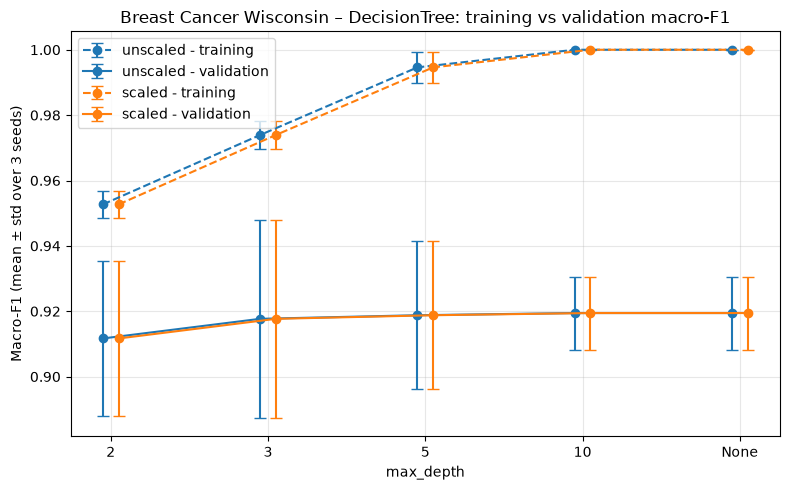

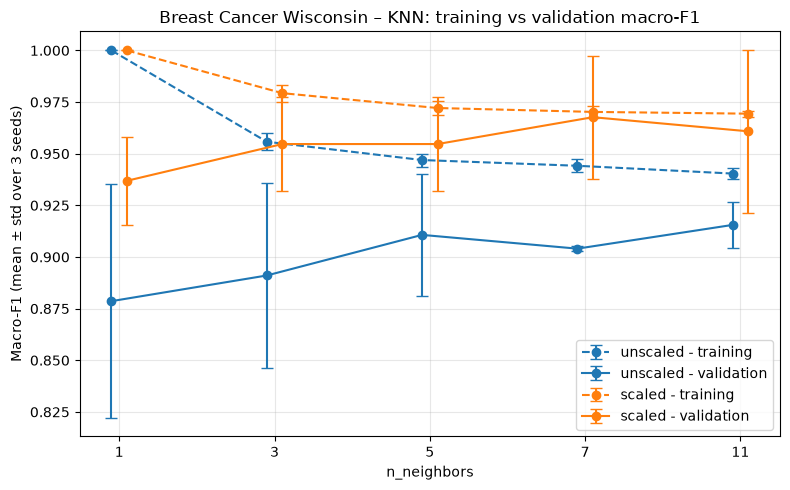

In [30]:
def plot_parameter_curve(algorithm, param_name, param_values, file_name):
    plt.figure(figsize=(8, 5))
    positions = np.arange(len(param_values))
    
    param_strings = []
    for val in param_values:
        param_strings.append(f"{param_name}={val}")

    part_unscaled = summary_table[(summary_table["algorithm"] == algorithm) & (summary_table["representation"] == "unscaled")]
    part_unscaled = part_unscaled.set_index("parameter").loc[param_strings]
    
    part_scaled = summary_table[(summary_table["algorithm"] == algorithm) & (summary_table["representation"] == "scaled")]
    part_scaled = part_scaled.set_index("parameter").loc[param_strings]

    plt.errorbar(positions - 0.05, part_unscaled["train_f1_macro_mean"], yerr=part_unscaled["train_f1_macro_std"],
                 color="tab:blue", linestyle="--", marker="o", capsize=4, label="unscaled - training")
    
    plt.errorbar(positions - 0.05, part_unscaled["val_f1_macro_mean"], yerr=part_unscaled["val_f1_macro_std"],
                 color="tab:blue", linestyle="-", marker="o", capsize=4, label="unscaled - validation")
                 
    plt.errorbar(positions + 0.05, part_scaled["train_f1_macro_mean"], yerr=part_scaled["train_f1_macro_std"],
                 color="tab:orange", linestyle="--", marker="o", capsize=4, label="scaled - training")
    
    plt.errorbar(positions + 0.05, part_scaled["val_f1_macro_mean"], yerr=part_scaled["val_f1_macro_std"],
                 color="tab:orange", linestyle="-", marker="o", capsize=4, label="scaled - validation")

    plt.xticks(positions, [str(v) for v in param_values])
    plt.xlabel(param_name)
    plt.ylabel("Macro-F1 (mean ± std over 3 seeds)")
    plt.title(f"Breast Cancer Wisconsin – {algorithm}: training vs validation macro-F1")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"figures/{DATASET_NAME}_{file_name}.png", dpi=150)
    plt.show()

plot_parameter_curve("DecisionTree", "max_depth", helpers.TREE_DEPTHS, "04_tree_depth_comparison")
plot_parameter_curve("KNN", "n_neighbors", helpers.NEIGHBOR_COUNTS, "05_knn_neighbors_comparison")

Standart sapma sadece bu üç tekrarlanan bölünmedeki değişkenliği anlatır güven aralığı veya istatistiksel anlamlılık kanıtı değildir.

**Yorum (Interpretation):** - **Seçilen konfigürasyon:** `knn_scaled_k7` (ortalama doğrulama macro-F1 = 0.9677, std = 0.0297).
- **Ölçekleme etkisi:** Karar ağacında scaled ve unscaled sonuçlar **tamamen aynı** (fark 0.0000). Ağaç her özelliği ayrı bir eşikle böler;
  StandardScaler değerlerin sırasını değiştirmediği için aynı bölmeler oluşur. KNN ölçeklemeden en çok etkilenen algoritma oldu:
  ortalama doğrulama macro-F1 değerleri ölçeklemeyle 0.0440 (k=5) ile 0.0636 (k=3 ve k=7) arasında arttı (örnek: k=7 için 0.9040 → 0.9677).
  GaussianNB'de küçük bir **düşüş** oldu (0.9369 → 0.9248). GaussianNB teoride ölçekten bağımsızdır; buradaki fark `var_smoothing` ayarından gelir.
  Bu ayar tüm varyanslara, en büyük özellik varyansının küçük bir oranını ekler. Ölçeklenmemiş veride en büyük varyans (area özellikleri) çok büyük olduğu için
  eklenen değer de farklı olur.
- **Ağaç derinliği:** Ortalama doğrulama macro-F1 derinlikle sadece biraz arttı (2: 0.9117, 3: 0.9177, 5: 0.9188, 10 ve None: 0.9195).
  Eğitim macro-F1 ise depth 10/None'da 1.0'a çıktı ve eğitim–doğrulama farkı 0.041'den 0.081'e büyüdü. Ağaç eğitim verisini ezberliyor (overfitting).
  depth=10 ve None aynı sonucu verdi, yani ağaçlar zaten 10 seviyeden önce duruyor.
- **Komşu sayısı:** Daha büyük k her zaman daha iyi değil. Scaled KNN için sıra: k=1: 0.9369, k=3: 0.9547, k=5: 0.9547, k=7: 0.9677, k=11: 0.9608.
  k=1 eğitimde 1.0 alıyor (her nokta kendi en yakın komşusu); bu yüzden eğitim–doğrulama farkı en büyük olan KNN ayarı (0.063).
- **Seed'ler arası değişkenlik:** Seçilen modelin üç seed'deki doğrulama macro-F1 değerleri 0.961, 0.942 ve 1.000. Doğrulama setinde sadece 57 örnek olduğu için
  tek bir örnek accuracy'yi yaklaşık 1.75 puan değiştirir. Standart sapmalar (0.01–0.04) ortalamalar arasındaki bazı farklardan büyük; bu yüzden
  birbirine yakın konfigürasyonlar arasındaki sıralama kesin değildir.

### 9. Evaluating the Selected Models on the Test Sets

- **Selection Frozen (Seçim Donduruldu):** The model selection is now completely frozen. *(Model seçimi artık tamamen dondurulmuştur.)*
- **Single Test (Tek Test):** We evaluate the chosen model (from seed 42) exactly once on the fixed test set. *(Seçilen konfigürasyonun seed 42 ile eğitilmiş halini, sabit test setinde sadece bir kez değerlendiriyoruz.)*
- **No Retraining (Yeniden Eğitim Yok):** We do not retrain the model on combined train+val data, and we do not test any other candidates. *(Modeli eğitim ve doğrulama verilerini birleştirerek yeniden eğitmiyoruz ve başka hiçbir modeli test etmiyoruz.)*

### 9.1 Final performance metrics

In [31]:
final_model = seed42_models[selected_config]

if selected_representation == "scaled":
    X_test_used = X_test_scaled
else:
    X_test_used = X_test

print(f"Final model: {selected_config}")
print(f"Representation: {selected_representation}")
print(f"Evaluation seed: {TEST_SEED}")

classes_list = [int(c) for c in final_model.classes_]
print(f"Probability column order (classes_): {classes_list}")

test_pred = final_model.predict(X_test_used)
test_proba = final_model.predict_proba(X_test_used)
test_scores = helpers.classification_metrics(y_test, test_pred, test_proba, final_model.classes_, DATASET_NAME)

undefined_classes = helpers.undefined_metric_classes(y_test.values, test_pred, final_model.classes_)
print(f"Undefined precision/recall on test (before zero_division): {undefined_classes}")

for name, value in test_scores.items():
    print(f"test {name}: {value:.4f}")

Final model: knn_scaled_k7
Representation: scaled
Evaluation seed: 42
Probability column order (classes_): [0, 1]
Undefined precision/recall on test (before zero_division): 
test accuracy: 0.9737
test precision_macro: 0.9800
test recall_macro: 0.9643
test f1_macro: 0.9713
test roc_auc: 0.9888


In [32]:
report_text = classification_report(y_test, test_pred, labels=class_labels, target_names=class_names, digits=4, zero_division=0)

report_dict = classification_report(y_test, test_pred, labels=class_labels, target_names=class_names, output_dict=True, zero_division=0)

report_df = pd.DataFrame(report_dict).T
report_df.to_csv(f"results/supporting/{DATASET_NAME}_test_classification_report.csv")

print(f"Classification report - {DATASET_NAME} - {selected_config}")
print("Test set results (seed 42):")
print(report_text)

Classification report - breast_cancer - knn_scaled_k7
Test set results (seed 42):
              precision    recall  f1-score   support

   malignant     1.0000    0.9286    0.9630        42
      benign     0.9600    1.0000    0.9796        72

    accuracy                         0.9737       114
   macro avg     0.9800    0.9643    0.9713       114
weighted avg     0.9747    0.9737    0.9735       114



In [33]:
final_test_table = pd.DataFrame([{
    "dataset": DATASET_NAME,
    "selected_config": selected_config,
    "evaluation_seed": TEST_SEED,
    "val_f1_macro_mean": selected_row["val_f1_macro_mean"],
    "val_f1_macro_std": selected_row["val_f1_macro_std"],
    "test_accuracy": test_scores["accuracy"],
    "test_precision_macro": test_scores["precision_macro"],
    "test_recall_macro": test_scores["recall_macro"],
    "test_f1_macro": test_scores["f1_macro"],
    "test_roc_auc": test_scores["roc_auc"]
}])

seed42_val = run_table[run_table["run_id"] == f"{DATASET_NAME}_{selected_config}_s42"]
val_f1_score = seed42_val["val_f1_macro"].iloc[0]

print(f"Seed-42 validation macro-F1 of this model: {val_f1_score:.4f}")

final_test_table.round(4)

Seed-42 validation macro-F1 of this model: 0.9615


,dataset,selected_config,evaluation_seed,val_f1_macro_mean,val_f1_macro_std,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro,test_roc_auc
0,breast_cancer,knn_scaled_k7,42,0.9677,0.0297,0.9737,0.98,0.9643,0.9713,0.9888


**Yorum (Interpretation):** Test sonuçları: accuracy 0.9737, macro precision 0.9800, macro recall 0.9643, macro-F1 0.9713, ROC-AUC 0.9888.
Test macro-F1, ortalama doğrulama macro-F1'den (0.9677) ve bu modelin seed-42 doğrulama skorundan (0.9615) biraz yüksek.
Fark, seed'ler arası standart sapma (0.0297) içinde kalıyor. Test seti de küçük (114 örnek), bu yüzden bu farkı "model testte daha iyi" diye yorumlamıyoruz.
Seçilen model bu sonuçtan sonra değiştirilmedi.

### 9.2 Confusion matrices
Satırlar **Actual**, sütunlar **Predicted**  olarak etiketlenir; hücrelerde sayılar vardır.

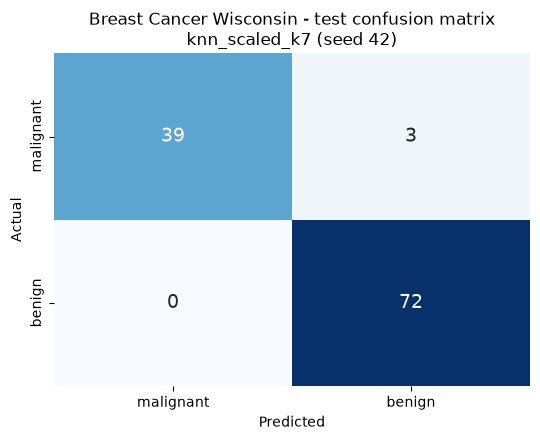

                  Predicted malignant  Predicted benign
Actual malignant                   39                 3
Actual benign                       0                72


In [34]:
cm = confusion_matrix(y_test, test_pred, labels=class_labels)

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 14},
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Breast Cancer Wisconsin - test confusion matrix\n{selected_config} (seed 42)")
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_06_confusion_matrix_test.png", dpi=150)
plt.show()

actual_names = ["Actual " + n for n in class_names]
predicted_names = ["Predicted " + n for n in class_names]

cm_display = pd.DataFrame(cm, index=actual_names, columns=predicted_names)
print(cm_display)

cm_csv = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_csv.to_csv(f"results/supporting/{DATASET_NAME}_test_confusion_matrix.csv")

Sınıf sırası **[0, 1] = [malignant, benign]** ve pozitif sınıf **malignant** olduğu için bu matris standart TN-FP/FN-TP
düzeninde **değildir**. Burada:
- `cm[0,0]` = **TP** 
- `cm[0,1]` = **FN** 
- `cm[1,0]` = **FP** 
- `cm[1,1]` = **TN** 

In [35]:
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]

print(f"TP = {TP}, FN = {FN}, FP = {FP}, TN = {TN}")

if (TP + FP) > 0:
    manual_precision = TP / (TP + FP)
else:
    manual_precision = None

if (TP + FN) > 0:
    manual_recall = TP / (TP + FN)
else:
    manual_recall = None

if manual_precision is None or manual_recall is None or (manual_precision + manual_recall) == 0:
    manual_f1 = None
else:
    manual_f1 = 2 * manual_precision * manual_recall / (manual_precision + manual_recall)

p_str = "undefined" if manual_precision is None else round(manual_precision, 4)
r_str = "undefined" if manual_recall is None else round(manual_recall, 4)
f1_str = "undefined" if manual_f1 is None else round(manual_f1, 4)

print(f"Manual precision = TP/(TP+FP) = {TP}/({TP}+{FP}) = {p_str}")
print(f"Manual recall = TP/(TP+FN) = {TP}/({TP}+{FN}) = {r_str}")
print(f"Manual F1 = 2PR/(P+R) = {f1_str}")

rep_precision = report_dict["malignant"]["precision"]
rep_recall = report_dict["malignant"]["recall"]
rep_f1 = report_dict["malignant"]["f1-score"]

manual_check = pd.DataFrame({
    "manual": [manual_precision, manual_recall, manual_f1],
    "classification_report (malignant row)": [rep_precision, rep_recall, rep_f1]
}, index=["precision", "recall", "f1"])

manual_check.to_csv(f"results/supporting/{DATASET_NAME}_manual_metric_check.csv")
manual_check.round(4)

TP = 39, FN = 3, FP = 0, TN = 72
Manual precision = TP/(TP+FP) = 39/(39+0) = 1.0
Manual recall = TP/(TP+FN) = 39/(39+3) = 0.9286
Manual F1 = 2PR/(P+R) = 0.963


,manual,classification_report (malignant row)
precision,1.0000,1.0000
recall,0.9286,0.9286
f1,0.9630,0.9630


**Yorum (Interpretation):** Matris: TP = 39, FN = 3, FP = 0, TN = 72. Üç hatanın üçü de **false negative**: gerçek malignant örnek benign olarak tahmin edilmiş.
Tıbbi açıdan en riskli hata türü budur, çünkü bir kanser vakası kaçırılmış olur. Hiç false positive (yanlış alarm) yok.
Elle hesaplanan malignant precision (39/39 = 1.0000), recall (39/42 = 0.9286) ve F1 (0.9630), classification report'taki **malignant satırıyla**
birebir aynı. Hiçbir payda sıfır olmadığı için tanımsız metrik yok.

### 9.3 ROC curves
ROC eğrisi farklı karar eşiklerinde True Positive Rate ile False Positive Rate i gösterir.
Bu grafik sadece betimleyicidir test setiyle yeni eşik seçilmez veya model ayarlanmaz.

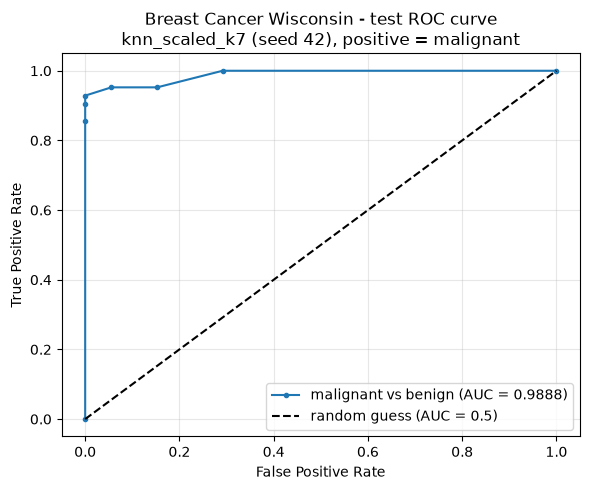

Number of distinct thresholds on the curve: 8


In [36]:
malignant_target = (y_test == 0).astype(int)
malignant_column = list(final_model.classes_).index(0)

malignant_probs = test_proba[:, malignant_column]

fpr, tpr, thresholds = roc_curve(malignant_target, malignant_probs)
auc_value = roc_auc_score(malignant_target, malignant_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, marker=".", label=f"malignant vs benign (AUC = {auc_value:.4f})")
plt.plot([0, 1], [0, 1], "k--", label="random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"Breast Cancer Wisconsin - test ROC curve\n{selected_config} (seed 42), positive = malignant")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"figures/{DATASET_NAME}_07_roc_test.png", dpi=150)
plt.show()

print(f"Number of distinct thresholds on the curve: {len(thresholds)}")

**Yorum (Interpretation):** Malignant-vs-benign ROC-AUC = 0.9888. Eğri basamaklı görünüyor çünkü k=7 olan KNN sadece 0, 1/7, 2/7, ..., 1 olasılıklarını üretebiliyor
(grafikte 8 farklı eşik var). **Eşik etkisi:** Malignant demek için gereken olasılık eşiğini düşürürsek daha çok örneğe malignant deriz.
Bu, false negative sayısını azaltır ama false positive sayısını artırır. Eşiği yükseltirsek tersi olur: daha az yanlış alarm ama daha çok kaçırılan vaka.
Bu notebook'ta eşik **değiştirilmedi**; ROC eğrisi sadece betimleyici olarak kullanıldı.

### 9.4 Error interpretation
Model testte 114 örneğin 111'ini doğru sınıflandırdı.
Üç hata da malignant vakaların benign tahmin edilmesinden kaynaklandı.
Hiç false positive oluşmadı.
Test başarısı yüksek olsa da tek bir test bölünmesi modelin her durumda kusursuz çalışacağını kanıtlamaz.
Model test sonuçlarına bakılarak yeniden ayarlanmadı.

In [37]:
actual_labels = [class_names[v] for v in y_test]
predicted_labels = [class_names[v] for v in test_pred]

test_results = pd.DataFrame({
    "actual": actual_labels,
    "predicted": predicted_labels
}, index=y_test.index)

for column, label in enumerate(final_model.classes_):
    col_name = f"P({class_names[label]})"
    test_results[col_name] = test_proba[:, column].round(4)

errors = test_results[test_results["actual"] != test_results["predicted"]].sort_index()

errors.to_csv(f"results/supporting/{DATASET_NAME}_test_errors.csv")

print(f"Number of test errors: {len(errors)} of {len(test_results)}")

errors

Number of test errors: 3 of 114


,actual,predicted,P(malignant),P(benign)
41,malignant,benign,0.4286,0.5714
73,malignant,benign,0.1429,0.8571
205,malignant,benign,0.1429,0.8571


In [38]:
if len(errors) == 0:
    print("The selected classifier made no test errors.")
else:
    example_index = errors.index[0]
    
    actual_name = errors.loc[example_index, "actual"]
    predicted_name = errors.loc[example_index, "predicted"]
    
    print(f"Example row index: {example_index} | actual: {actual_name} | predicted: {predicted_name}")
    
    actual_label = class_names.index(actual_name)
    predicted_label = class_names.index(predicted_name)
    
    train_42_X = splits[42]["X_train"]
    train_42_y = splits[42]["y_train"]
    
    actual_mean = train_42_X[train_42_y == actual_label].mean()
    predicted_mean = train_42_X[train_42_y == predicted_label].mean()
    
    comparison = pd.DataFrame({
        "value": X_test.loc[example_index],
        f"train_mean_{actual_name}": actual_mean,
        f"train_mean_{predicted_name}": predicted_mean
    })
    
    diff_actual = (comparison["value"] - comparison[f"train_mean_{actual_name}"]).abs()
    diff_predicted = (comparison["value"] - comparison[f"train_mean_{predicted_name}"]).abs()
    
    closer_to_actual = diff_actual < diff_predicted
    comparison["closer_to"] = np.where(closer_to_actual, actual_name, predicted_name)
    
    predicted_count = (comparison["closer_to"] == predicted_name).sum()
    total_features = len(comparison)
    
    print(f"Features closer to the PREDICTED class mean: {predicted_count} of {total_features}")
    
    display(comparison.round(4))

Example row index: 41 | actual: malignant | predicted: benign
Features closer to the PREDICTED class mean: 19 of 30


,value,train_mean_malignant,train_mean_benign,closer_to
mean radius,10.9500,17.4725,12.1000,benign
mean texture,21.3500,21.5791,17.6261,malignant
mean perimeter,71.9000,115.5578,77.7604,benign
mean area,371.1000,978.0933,459.5831,benign
mean smoothness,0.1227,0.1039,0.0922,malignant
mean compactness,0.1218,0.1490,0.0793,malignant
mean concavity,0.1044,0.1672,0.0465,benign
mean concave points,0.0567,0.0899,0.0253,benign
mean symmetry,0.1895,0.1938,0.1722,malignant
mean fractal dimension,0.0687,0.0631,0.0629,malignant


### 10. K-Means Clustering

K-Means **gözetimsiz (unsupervised)** bir yöntemdir: `fit` sırasında etiket görmez. Bulduğu küme numaraları
sınıf etiketi değildir. Bu veri seti için `n_clusters=2` (sınıf sayısına göre sabit bir karşılaştırma ayarı; aramayla seçilmedi),
`random_state=seed`, `n_init=10` kullanılır. `n_init=10`, her fit içinde 10 farklı başlangıç merkezi denenip en iyisinin
(en düşük inertia) tutulması demektir; 10 ayrı deney değildir.

### 10.1 Fit the clustering model
3 seed × 2 temsil = **6 K-Means fit**. Sınıflandırıcılarla aynı eğitim indeksleri kullanılır.

In [39]:
kmeans_runs, kmeans_models = helpers.run_kmeans_experiments(DATASET_NAME, splits, SEEDS, n_clusters=2)
print("Number of K-Means fits:", len(kmeans_runs))
assert len(kmeans_runs) == 6
kmeans_runs.round(4)

Number of K-Means fits: 6


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette
0,breast_cancer,breast_cancer_kmeans_unscaled_s42,42,unscaled,2,10,5.156538e+07,0.3995,0.6387
1,breast_cancer,breast_cancer_kmeans_scaled_s42,42,scaled,2,10,7.918810e+03,0.4516,0.2854
2,breast_cancer,breast_cancer_kmeans_unscaled_s52,52,unscaled,2,10,4.919078e+07,0.6122,0.6975
3,breast_cancer,breast_cancer_kmeans_scaled_s52,52,scaled,2,10,8.003001e+03,0.5586,0.3750
4,breast_cancer,breast_cancer_kmeans_unscaled_s62,62,unscaled,2,10,5.305649e+07,0.5013,0.6958
5,breast_cancer,breast_cancer_kmeans_scaled_s62,62,scaled,2,10,7.922515e+03,0.7336,0.2758


In [40]:
kmeans_summary = kmeans_runs.groupby("representation").agg(
    train_inertia_mean=("train_inertia", "mean"),
    train_inertia_std=("train_inertia", "std"),
    val_ari_mean=("val_ari", "mean"),
    val_ari_std=("val_ari", "std"),
    val_silhouette_mean=("val_silhouette", "mean"),    
    val_silhouette_std=("val_silhouette", "std"),
    n_valid_silhouette=("val_silhouette", "count"),
    n_seeds=("seed", "count"),
).reindex(["unscaled", "scaled"]).reset_index()
kmeans_summary.insert(0, "dataset", DATASET_NAME)
kmeans_summary.round(4)

,dataset,representation,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,n_valid_silhouette,n_seeds
0,breast_cancer,unscaled,5.127088e+07,1.949607e+06,0.5043,0.1064,0.6773,0.0334,3,3
1,breast_cancer,scaled,7.948109e+03,4.757430e+01,0.5813,0.1424,0.3121,0.0547,3,3


Her veri setinde 2 temsil × 3 seed = 6 fit yapılır.
İki veri setinde toplam 12 K-Means fit vardır.
n_init=10, her fit sırasında 10 farklı başlangıç denenmesidir; 10 ayrı deney değildir.
inertia, örneklerin kendi küme merkezlerine olan uzaklıklarının kareleri toplamıdır.
ARI, gerçek sınıflarla kümelerin ne kadar uyuştuğunu ölçer.
Silhouette, kümelerin ne kadar ayrıştığını ölçer.

### 10.2 Final cluster evaluation on the fixed test sets
Seed 42 ile **zaten eğitilmiş** iki K-Means modeli test setinde `predict` ile kullanılır.
İki temsil de raporlanır; daha iyi olanı seçmiyoruz.

In [41]:
kmeans_test_rows = []
test_clusters = {}
for representation in ["unscaled", "scaled"]:
    if representation == "scaled":
        X_test_rep = X_test_scaled
    else:
        X_test_rep = X_test
    clusters = kmeans_models[representation].predict(X_test_rep)
    test_clusters[representation] = clusters
    ari, silhouette = helpers.cluster_scores(X_test_rep, y_test, clusters)
    counts = pd.Series(clusters).value_counts().sort_index()
    kmeans_test_rows.append({
        "dataset": DATASET_NAME,
        "representation": representation,
        "evaluation_seed": TEST_SEED,
        "n_test_samples": len(clusters),
        "cluster_counts": counts.to_dict(),
        "test_ari": ari,
        "test_silhouette": silhouette,
    })
kmeans_test_table = pd.DataFrame(kmeans_test_rows)
kmeans_test_table.round(4)

,dataset,representation,evaluation_seed,n_test_samples,cluster_counts,test_ari,test_silhouette
0,breast_cancer,unscaled,42,114,"{0: 86, 1: 28}",0.5585,0.7120
1,breast_cancer,scaled,42,114,"{0: 74, 1: 40}",0.7354,0.3251


In [42]:
for representation in ["unscaled", "scaled"]:
    actual_labels = [class_names[v] for v in y_test]
    table = pd.crosstab(pd.Series(actual_labels, name="actual class"),
                        pd.Series(test_clusters[representation], name="cluster ID"))
    print(f"\n{DATASET_NAME} - {representation} - seed 42 - TEST set")
    display(table)
    table.to_csv(f"results/supporting/{DATASET_NAME}_kmeans_contingency_{representation}.csv")


breast_cancer - unscaled - seed 42 - TEST set


cluster ID,0,1
actual class,,
benign,72,0
malignant,14,28



breast_cancer - scaled - seed 42 - TEST set


cluster ID,0,1
actual class,,
benign,69,3
malignant,5,37


ARI (Adjusted Rand Index), iki bölümlemenin (gerçek sınıflar ve kümeler) ne kadar uyuştuğunu şans etkisini düzelterek ölçer;
küme numaralarının sınıf numaralarıyla aynı olmasını gerektirmez. Etiketler sadece **değerlendirmede** kullanılır.
Burada sınıf etiketleri ile küme numaralarını doğrudan karşılaştıran accuracy veya sınıflandırma confusion matrix'i **hesaplanmaz**.

### 10.3 Visualise and interpret the clusters
Grafik için iki orijinal özellik **seed 42 eğitim verisi** ile seçilir: ANOVA F-skoru (`f_classif`) en yüksek özellik birinci seçilir;
ikinci özellik, birinciyle eğitim verisindeki mutlak korelasyonu 0.7'den küçük olanlar arasında F-skoru en yüksek olandır
(çok benzer iki özellik seçip düz bir çizgi görmemek için). Aynı iki özellik her iki temsil için kullanılır.

In [43]:
train_42 = splits[42]["X_train"]
f_scores, _ = f_classif(train_42, splits[42]["y_train"])
f_scores = pd.Series(f_scores, index=X.columns).sort_values(ascending=False)
feature_1 = f_scores.index[0]
train_correlation = train_42.corr()[feature_1].abs()
feature_2 = None
for f in f_scores.index:
    if f != feature_1 and train_correlation[f] < 0.7:
        feature_2 = f
        break
print("Chosen features (seed-42 training data):", feature_1, "and", feature_2)
print(f"F-scores: {f_scores[feature_1]:.1f} and {f_scores[feature_2]:.1f}, |r| between them = {train_correlation[feature_2]:.3f}")

Chosen features (seed-42 training data): worst concave points and radius error
F-scores: 770.0 and 194.6, |r| between them = 0.544


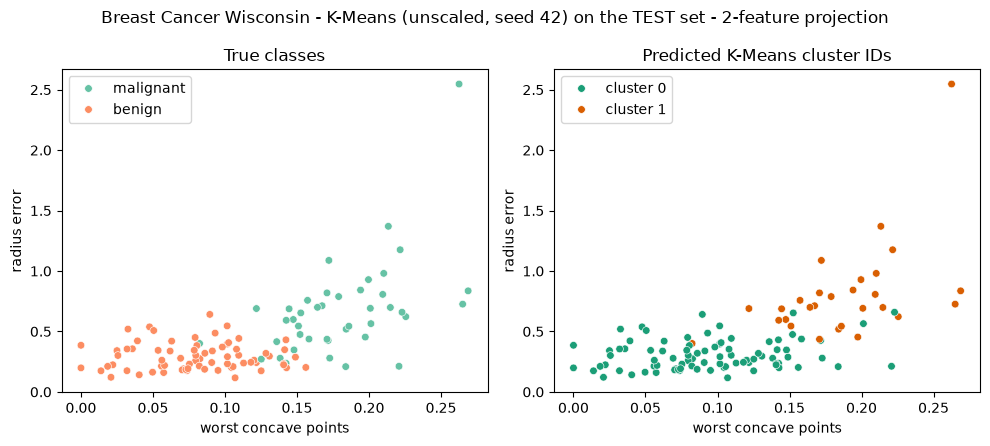

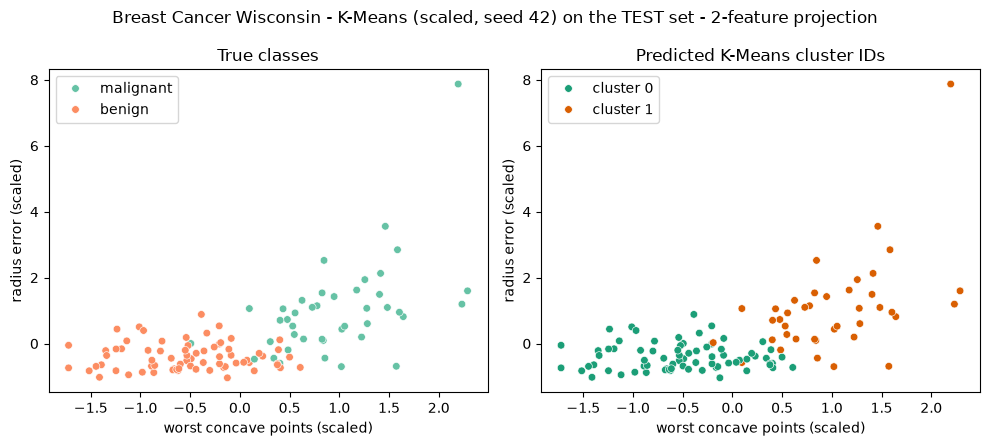

In [44]:
for representation in ["unscaled", "scaled"]:
    if representation == "scaled":
        X_test_rep = X_test_scaled
        suffix = " (scaled)"
    else:
        X_test_rep = X_test
        suffix = ""

    fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

    true_names = [class_names[v] for v in y_test]
    sns.scatterplot(x=X_test_rep[feature_1], y=X_test_rep[feature_2], hue=true_names,
                    hue_order=class_names, palette="Set2", ax=axes[0], s=30)
    axes[0].set_title("True classes")

    cluster_names = [f"cluster {c}" for c in test_clusters[representation]]
    sns.scatterplot(x=X_test_rep[feature_1], y=X_test_rep[feature_2], hue=cluster_names,
                    hue_order=sorted(set(cluster_names)), palette="Dark2", ax=axes[1], s=30)
    axes[1].set_title("Predicted K-Means cluster IDs")

    for ax in axes:
        ax.set_xlabel(feature_1 + suffix)
        ax.set_ylabel(feature_2 + suffix)

    fig.suptitle(f"Breast Cancer Wisconsin - K-Means ({representation}, seed 42) on the TEST set - 2-feature projection")
    fig.tight_layout()
    fig.savefig(f"figures/{DATASET_NAME}_08_kmeans_{representation}_test.png", dpi=150)
    plt.show()

**Yorum (Interpretation):** - **Doğrulama (6 fit):** Ortalama ARI unscaled'da 0.5043 (std 0.1064), scaled'da 0.5813 (std 0.1424). Üç seed'de de silhouette tanımlı (3/3).
  Unscaled silhouette (0.6773) scaled'dan (0.3121) yüksek görünüyor, ancak silhouette özellik uzayına bağlı olduğu için bu iki değeri doğrudan karşılaştırmıyoruz.
- **Test (seed 42):** Unscaled kümeler 86/28, ARI = 0.5585. Çapraz tabloda 72 benign örneğin hepsi cluster 0'da; 42 malignant örneğin 14'ü cluster 0'a, 28'i cluster 1'e düşmüş.
  Yani unscaled K-Means büyük tümörleri ayırıyor, küçük malignant örnekleri benign'larla karıştırıyor. Bunun nedeni, ölçeklenmemiş uzayda mesafeyi area gibi
  büyük değerli özelliklerin belirlemesi. Bu tek boyutlu ayrım yüksek silhouette (0.7120) verir ama sınıflarla daha az uyumludur.
  Scaled kümeler 74/40, ARI = 0.7354. 69 benign + 5 malignant cluster 0'da, 3 benign + 37 malignant cluster 1'de; sınıflarla daha uyumlu.
- **Grafikler:** Seed-42 eğitim verisiyle seçilen iki özellik **worst concave points** ve **radius error**. Scaled grafikte kümeler kabaca
  worst concave points değerine göre ayrılıyor ve sınıflara benziyor; sınır bölgesinde iki sınıf karışık. Model 30 özelliğin hepsini kullandı;
  grafik sadece iki özelliğe izdüşüm (projection) olduğundan bazı noktalar yanlış kümede gibi görünebilir.
- **Bilgi farkı:** Üç sınıflandırıcı eğitimde `y_train` etiketlerini görür ve doğrudan sınıfları ayırmayı öğrenir. K-Means ise etiket görmez;
  sadece özellikler arası mesafeye ve sabit küme sayısına (k=2) göre noktaları gruplar. Etiketler yalnızca sonradan ARI ve çapraz tablo ile değerlendirme için kullanıldı.

### 12. Required Run and Output Inventory (this dataset)

Bu bölüm bu veri setinin sonuçlarını iki veri setinin **ortak** CSV dosyalarına (`results/` klasörü) yazar ve sayıları kontrol eder.
Her CSV'de `dataset` sütunu vardır. Diğer notebook da kendi satırlarını aynı dosyalara ekler.
Destekleyici tablolar (betimleyici istatistikler, bölünme özeti, sınıflandırma raporu, confusion matrix, elle hesap, çapraz tablolar)
yukarıdaki hücrelerde `results/supporting/` klasörüne kaydedildi.
Bölüm 11 (iki veri setinin karşılaştırması) her iki notebook'un sonucuna ihtiyaç duyduğu için `report.docx` içindedir.

In [45]:
outputs = {
    "classifier_runs.csv": run_table[["dataset"] + run_columns + ["config_id", "val_undefined_before_zero_division"]],
    "classifier_summary.csv": summary_table.drop(columns=["setting"]),
    "classifier_test.csv": final_test_table,
    "kmeans_runs.csv": kmeans_runs,
    "kmeans_summary.csv": kmeans_summary,
    "kmeans_test.csv": kmeans_test_table,
}

for file_name, table in outputs.items():
    helpers.save_combined_csv(table, file_name, DATASET_NAME)
    print(file_name, ":", len(table), "rows for", DATASET_NAME)

total_fits = len(run_table) + len(kmeans_runs)
print("\nModel fits in this notebook:", len(run_table), "classifier +", len(kmeans_runs), "K-Means =", total_fits)

figure_files = []
for f in os.listdir("figures"):
    if f.startswith(DATASET_NAME):
        figure_files.append(f)
print("Figure files for this dataset:", sorted(figure_files))

classifier_runs.csv : 66 rows for breast_cancer
classifier_summary.csv : 22 rows for breast_cancer
classifier_test.csv : 1 rows for breast_cancer
kmeans_runs.csv : 6 rows for breast_cancer
kmeans_summary.csv : 2 rows for breast_cancer
kmeans_test.csv : 2 rows for breast_cancer

Model fits in this notebook: 66 classifier + 6 K-Means = 72
Figure files for this dataset: ['breast_cancer_01_class_distribution.png', 'breast_cancer_02_correlation_heatmap.png', 'breast_cancer_03_boxplots_part1.png', 'breast_cancer_03_boxplots_part2.png', 'breast_cancer_04_tree_depth_comparison.png', 'breast_cancer_05_knn_neighbors_comparison.png', 'breast_cancer_06_confusion_matrix_test.png', 'breast_cancer_07_roc_test.png', 'breast_cancer_08_kmeans_scaled_test.png', 'breast_cancer_08_kmeans_unscaled_test.png']
